In [1]:
!pip -q install torchinfo thop

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split
from torchinfo import summary
from thop import profile

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

full_train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [55000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.2MB/s]

Train: 55000
Validation: 5000
Test: 10000


In [3]:


class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 10)
        )

    def forward(self, x):
        return self.network(x)


class AttentionModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.patch_projection = nn.Linear(7 * 7, 64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=128,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.classifier = nn.Linear(64, 10)

    def forward(self, x):

        patches = x.unfold(2, 7, 7).unfold(3, 7, 7)
        patches = patches.contiguous().view(x.size(0), 16, 49)

        x = self.patch_projection(patches)
        x = self.encoder(x)
        x = x.mean(dim=1)
        return self.classifier(x)


models = {
    "MLP": MLP().to(device),
    "CNN": CNN().to(device),
    "Attention": AttentionModel().to(device)
}

dummy_input = torch.zeros(2, 1, 28, 28, device=device)

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        output = model(dummy_input)

    parameters = sum(p.numel() for p in model.parameters())
    assert output.shape == (2, 10)

    print(f"{name}: output={tuple(output.shape)}, parameters={parameters:,}")

MLP: output=(2, 10), parameters=235,146
CNN: output=(2, 10), parameters=20,490
Attention: output=(2, 10), parameters=70,794


In [5]:


parameter_counts = {}

for name, model in models.items():
    print(f"\n{name} MODEL")

    model_summary = summary(
        model,
        input_size=(1, 1, 28, 28),
        col_names=["input_size", "output_size", "num_params"],
        depth=4,
        device=device,
        mode="eval",
        verbose=0
    )

    print(model_summary)

    parameter_counts[name] = model_summary.total_params

    assert parameter_counts[name] == sum(
        p.numel() for p in model.parameters()
    )

print("\nTotal parameters:")
for name, count in parameter_counts.items():
    print(f"{name}: {count:,}")


MLP MODEL
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
MLP                                      [1, 1, 28, 28]            [1, 10]                   --
├─Sequential: 1-1                        [1, 1, 28, 28]            [1, 10]                   --
│    └─Flatten: 2-1                      [1, 1, 28, 28]            [1, 784]                  --
│    └─Linear: 2-2                       [1, 784]                  [1, 256]                  200,960
│    └─ReLU: 2-3                         [1, 256]                  [1, 256]                  --
│    └─Linear: 2-4                       [1, 256]                  [1, 128]                  32,896
│    └─ReLU: 2-5                         [1, 128]                  [1, 128]                  --
│    └─Linear: 2-6                       [1, 128]                  [1, 10]                   1,290
Total params: 235,146
Trainable params: 235,146
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0

In [6]:

mlp_first_layer = 2 * 784 * 256
mlp_flops = (
    mlp_first_layer
    + 2 * 256 * 128
    + 2 * 128 * 10
)

cnn_first_layer = 2 * 3 * 3 * 1 * 16 * 28 * 28
cnn_flops = (
    cnn_first_layer
    + 2 * 3 * 3 * 16 * 32 * 14 * 14
    + 2 * (32 * 7 * 7) * 10
)

seq = 16
d = 64
ff = 128

patch_projection = 2 * seq * 49 * d

qkv = 2 * seq * d * (3 * d)
attention_scores = 2 * seq * seq * d
weighted_values = 2 * seq * seq * d
output_projection = 2 * seq * d * d
feedforward = 2 * seq * d * ff + 2 * seq * ff * d

encoder_layer_flops = (
    qkv
    + attention_scores
    + weighted_values
    + output_projection
    + feedforward
)

attention_flops = (
    patch_projection
    + 2 * encoder_layer_flops
    + 2 * d * 10
)

manual_flops = {
    "MLP": mlp_flops,
    "CNN": cnn_flops,
    "Attention": attention_flops
}

print("Representative layer calculations:")
print(f"MLP first Linear: 2 × 784 × 256 = {mlp_first_layer:,}")
print(f"CNN first Conv: 2 × 3 × 3 × 1 × 16 × 28 × 28 = {cnn_first_layer:,}")
print(f"Attention QKV: 2 × 16 × 64 × 192 = {qkv:,}")

print("\nTotal estimated FLOPs per image:")
for name, flops in manual_flops.items():
    print(f"{name}: {flops:,}")

Representative layer calculations:
MLP first Linear: 2 × 784 × 256 = 401,408
CNN first Conv: 2 × 3 × 3 × 1 × 16 × 28 × 28 = 225,792
Attention QKV: 2 × 16 × 64 × 192 = 393,216

Total estimated FLOPs per image:
MLP: 469,504
CNN: 2,063,488
Attention: 2,329,856


In [8]:


import copy

profiling_results = {}

previous_fastpath = torch.backends.mha.get_fastpath_enabled()
torch.backends.mha.set_fastpath_enabled(False)

try:
    for name, model in models.items():
        profile_model = copy.deepcopy(model).to(device).eval()
        dummy_input = torch.zeros(1, 1, 28, 28, device=device)

        with torch.no_grad():
            macs, _ = profile(
                profile_model,
                inputs=(dummy_input,),
                verbose=False
            )

        estimated_flops = 2 * macs

        profiling_results[name] = {
            "manual_flops": manual_flops[name],
            "thop_macs": macs,
            "thop_flops_estimate": estimated_flops
        }

        print(f"\n{name}")
        print(f"Manual FLOPs: {manual_flops[name]:,}")
        print(f"THOP MACs: {macs:,.0f}")
        print(f"2 × THOP MACs: {estimated_flops:,.0f}")

finally:
    torch.backends.mha.set_fastpath_enabled(previous_fastpath)

print("\nNote: 2 × MACs is an approximate FLOPs conversion.")
print("Default THOP hooks may omit MultiheadAttention operations.")
print("Normalization counting can also cause differences.")


MLP
Manual FLOPs: 469,504
THOP MACs: 234,752
2 × THOP MACs: 469,504

CNN
Manual FLOPs: 2,063,488
THOP MACs: 1,031,744
2 × THOP MACs: 2,063,488

Attention
Manual FLOPs: 2,329,856
THOP MACs: 591,488
2 × THOP MACs: 1,182,976

Note: 2 × MACs is an approximate FLOPs conversion.
Default THOP hooks may omit MultiheadAttention operations.
Normalization counting can also cause differences.


In [9]:


import time
import platform

@torch.inference_mode()
def measure_latency(model, batch_size, runs):
    model.eval()
    x = torch.randn(batch_size, 1, 28, 28, device=device)


    for _ in range(10):
        model(x)

    if device.type == "cuda":
        torch.cuda.synchronize()

    times_ms = []

    for _ in range(runs):
        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()
        model(x)

        if device.type == "cuda":
            torch.cuda.synchronize()

        times_ms.append((time.perf_counter() - start) * 1000)

    return float(np.median(times_ms))


latency_results = {}

print("Device:", device)
print("PyTorch:", torch.__version__)
print("CPU threads:", torch.get_num_threads())
print("Platform:", platform.platform())

for name, model in models.items():
    batch1_ms = measure_latency(model, batch_size=1, runs=100)
    batch128_ms = measure_latency(model, batch_size=128, runs=20)

    latency_results[name] = {
        "batch1_ms": batch1_ms,
        "batch128_ms": batch128_ms
    }

    print(f"\n{name}")
    print(f"Batch 1 median (100 runs): {batch1_ms:.4f} ms")
    print(f"Batch 128 median (20 runs): {batch128_ms:.4f} ms")

Device: cpu
PyTorch: 2.11.0+cpu
CPU threads: 1
Platform: Linux-6.6.122+-x86_64-with-glibc2.39

MLP
Batch 1 median (100 runs): 0.0824 ms
Batch 128 median (20 runs): 0.9236 ms

CNN
Batch 1 median (100 runs): 0.3131 ms
Batch 128 median (20 runs): 28.4523 ms

Attention
Batch 1 median (100 runs): 0.4903 ms
Batch 128 median (20 runs): 19.3604 ms


In [10]:


from tqdm.auto import tqdm

criterion = nn.CrossEntropyLoss()
history = {}
test_accuracy = {}


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100 * correct / total


for name, model in models.items():
    print(f"\nTraining {name}", flush=True)

    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history[name] = []

    train_loader.generator.manual_seed(SEED)

    for epoch in range(1, 6):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for images, labels in tqdm(
            train_loader,
            desc=f"{name} | Epoch {epoch}/5"
        ):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_acc = 100 * correct / total
        val_loss, val_acc = evaluate(model, val_loader)

        history[name].append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

        print(
            f"Epoch {epoch}/5 | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: {train_acc:.2f}% | "
            f"Validation accuracy: {val_acc:.2f}%",
            flush=True
        )

    test_loss, test_acc = evaluate(model, test_loader)
    test_accuracy[name] = test_acc

    print(f"{name} TEST ACCURACY: {test_acc:.2f}%", flush=True)

print("\nFINAL TEST RESULTS")
for name, accuracy in test_accuracy.items():
    print(f"{name}: {accuracy:.2f}%")


Training MLP


MLP | Epoch 1/5:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 1/5 | Train loss: 0.4949 | Train accuracy: 82.11% | Validation accuracy: 85.54%


MLP | Epoch 2/5:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 2/5 | Train loss: 0.3548 | Train accuracy: 86.95% | Validation accuracy: 87.18%


...

Epoch 3/5 | Train loss: 0.4850 | Train accuracy: 82.55% | Validation accuracy: 83.04%


Attention | Epoch 4/5:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 4/5 | Train loss: 0.4541 | Train accuracy: 83.63% | Validation accuracy: 83.36%


Attention | Epoch 5/5:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 5/5 | Train loss: 0.4294 | Train accuracy: 84.36% | Validation accuracy: 83.06%
Attention TEST ACCURACY: 83.15%

FINAL TEST RESULTS
MLP: 87.63%
CNN: 90.03%
Attention: 83.15%


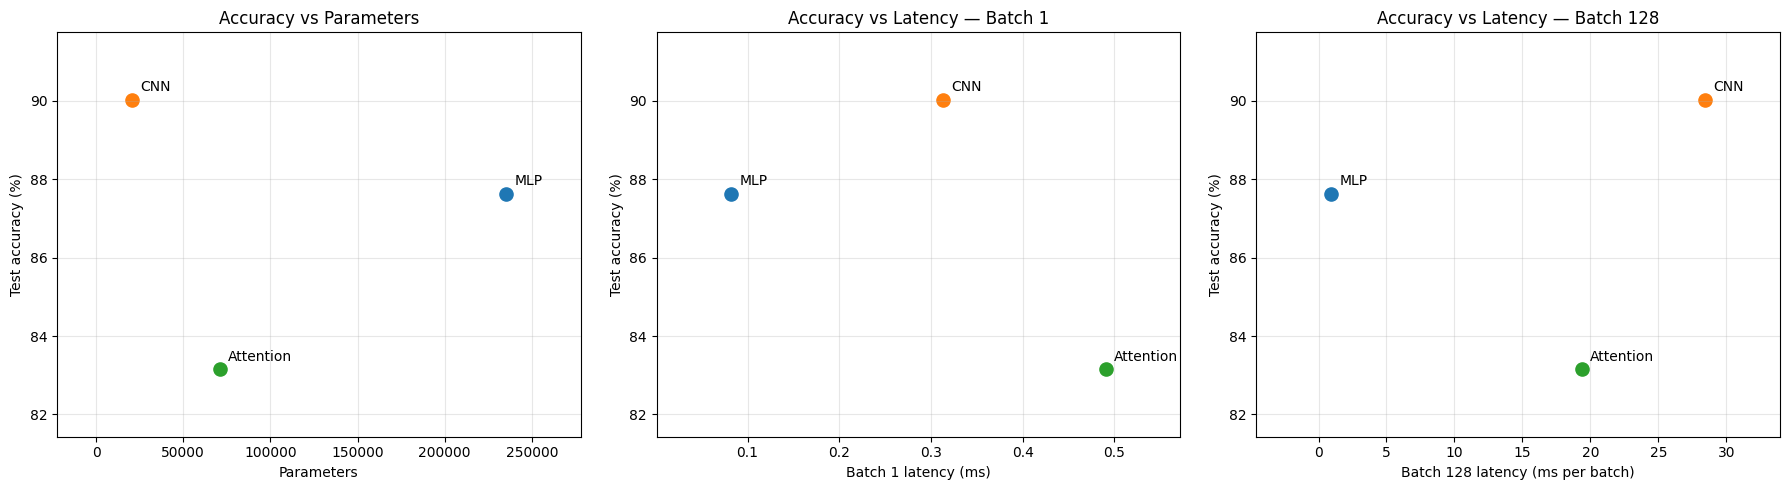

In [11]:
# TASK 5: Accuracy versus parameters and latency

names = list(models.keys())
accuracies = [test_accuracy[name] for name in names]
parameters = [parameter_counts[name] for name in names]

comparisons = [
    (parameters, "Parameters", "Accuracy vs Parameters"),
    (
        [latency_results[name]["batch1_ms"] for name in names],
        "Batch 1 latency (ms)",
        "Accuracy vs Latency — Batch 1"
    ),
    (
        [latency_results[name]["batch128_ms"] for name in names],
        "Batch 128 latency (ms per batch)",
        "Accuracy vs Latency — Batch 128"
    )
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ["tab:blue", "tab:orange", "tab:green"]

for ax, (x_values, xlabel, title) in zip(axes, comparisons):
    for name, x, accuracy, color in zip(
        names, x_values, accuracies, colors
    ):
        ax.scatter(x, accuracy, color=color, s=90)
        ax.annotate(
            name,
            (x, accuracy),
            xytext=(6, 6),
            textcoords="offset points"
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.margins(x=0.2, y=0.25)

fig.tight_layout()
fig.savefig("tradeoff_plots.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
from pathlib import Path

report = """# Lab 3: Architectures and Their Costs

## Setup
I compared an MLP, a CNN and an attention model on Fashion-MNIST.
I used 55,000 training, 5,000 validation and 10,000 test images.
I applied ToTensor() and Normalize((0.2860,), (0.3530,)).
Each model was trained for 5 epochs with Adam, lr=0.001 and batch size 128.

I followed the architectures listed in the manual. Their parameter
counts do not match the stated 100k-150k target, so this comparison
uses models of different sizes.

## Results
| Model | Parameters | Test accuracy | Batch 1 (ms) | Batch 128 (ms) |
|---|---:|---:|---:|---:|
"""

for name in models:
    report += (
        f"| {name} | {parameter_counts[name]:,} "
        f"| {test_accuracy[name]:.2f}% "
        f"| {latency_results[name]['batch1_ms']:.4f} "
        f"| {latency_results[name]['batch128_ms']:.4f} |\n"
    )

report += f"""
Latency was measured before training on {device}, using
PyTorch {torch.__version__} and {torch.get_num_threads()} CPU thread(s).
I used eval and inference modes, 10 warm-up runs, and the median of
100 runs for batch 1 and 20 runs for batch 128. Data loading was
excluded. Batch 128 values are times for the whole batch.

## Computation
I used 2 FLOPs per multiply-accumulate operation.
Example calculations for one image:

- Linear: 2 * 784 * 256 = 401,408 FLOPs.
- Conv: 2 * 3 * 3 * 1 * 16 * 28 * 28 = 225,792 FLOPs.
- Attention QKV: 2 * 16 * 64 * 192 = 393,216 FLOPs.

| Model | Manual FLOPs | THOP MACs | 2 * THOP MACs |
|---|---:|---:|---:|
"""

for name in models:
    result = profiling_results[name]
    report += (
        f"| {name} | {manual_flops[name]:,} "
        f"| {result['thop_macs']:,.0f} "
        f"| {result['thop_flops_estimate']:,.0f} |\n"
    )

report += """
The manual totals count the main matrix and convolution operations,
excluding bias, activations, pooling, normalization and softmax.
MLP and CNN matched THOP after the MAC-to-FLOP conversion.
THOP missed the full MultiheadAttention cost and included
normalization, which explains the attention difference.

## Plots
![Trade-off plots](tradeoff_plots.png)

## My conclusion
The CNN had the highest accuracy and the fewest parameters.
Its local filters reuse weights across image positions, making
it a good choice when accuracy and model size matter.

The MLP was fastest on this CPU. It uses dense matrix operations,
and batching reuses weights across images. It needs more parameters
but is a good choice when latency matters most.

Attention compares all patch pairs and needs extra intermediate
data such as Q, K, V and attention scores. It was less accurate here.
This version has no positional encoding, so mean pooling loses
patch-order information.

For this experiment, I would choose CNN for accuracy and compactness,
or MLP for speed. The results are from one five-epoch run with
different model sizes, so they do not show a universal winner.
"""

Path("report.md").write_text(report, encoding="utf-8")
print(report)
print("\nreport.md created successfully.")

# Lab 3: Architectures and Their Costs

## Setup
I compared an MLP, a CNN and an attention model on Fashion-MNIST.
I used 55,000 training, 5,000 validation and 10,000 test images.
I applied ToTensor() and Normalize((0.2860,), (0.3530,)).
Each model was trained for 5 epochs with Adam, lr=0.001 and batch size 128.

I followed the architectures listed in the manual. Their parameter
counts do not match the stated 100k-150k target, so this comparison
uses models of different sizes.

## Results
| Model | Parameters | Test accuracy | Batch 1 (ms) | Batch 128 (ms) |
|---|---:|---:|---:|---:|
| MLP | 235,146 | 87.63% | 0.0824 | 0.9236 |
| CNN | 20,490 | 90.03% | 0.3131 | 28.4523 |
| Attention | 70,794 | 83.15% | 0.4903 | 19.3604 |

Latency was measured before training on cpu, using
PyTorch 2.11.0+cpu and 1 CPU thread(s).
I used eval and inference modes, 10 warm-up runs, and the median of
100 runs for batch 1 and 20 runs for batch 128. Data loading was
excluded. Batch 128 values are times for th